# EDA 01b — Iranian Churn Dataset (UCI id 563)

**Mục tiêu:** Phân tích khám phá bộ dữ liệu **Iranian Churn** (`data/raw/iranian-uci/Customer Churn.csv`), kiểm tra trùng lặp dữ liệu từ `audit_report.json`, khảo sát phân bố biến phân loại/biến số theo nhãn `Churn`, phát hiện đa cộng tuyến và rủi ro rò rỉ thời gian, từ đó rút ra **"Phát hiện → Hệ quả cho mô hình"**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_EDA_DIR = PROJECT_ROOT / "figures" / "eda"
FIGURES_EDA_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", palette="colorblind")
print("PROJECT_ROOT:", PROJECT_ROOT)
print("FIGURES_EDA_DIR:", FIGURES_EDA_DIR)

PROJECT_ROOT: C:\Users\Admin\Documents\ML\telco-churn-prediction
FIGURES_EDA_DIR: C:\Users\Admin\Documents\ML\telco-churn-prediction\figures\eda


## 1. Nạp dữ liệu, kích thước, kiểu dữ liệu & giá trị thiếu

In [2]:
IRANIAN_PATH = PROJECT_ROOT / "data" / "raw" / "iranian-uci" / "Customer Churn.csv"
AUDIT_PATH = PROJECT_ROOT / "results" / "dataset_runs" / "iranian" / "audit_report.json"

df = pd.read_csv(IRANIAN_PATH)
df.columns = df.columns.astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"Tổng số giá trị thiếu (NaN): {int(df.isna().sum().sum())}")
display(df.head(3))
display(df.dtypes.to_frame("dtype"))

Kích thước: 3,150 dòng × 14 cột
Tổng số giá trị thiếu (NaN): 0


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0


,dtype
Call Failure,int64
Complains,int64
Subscription Length,int64
Charge Amount,int64
Seconds of Use,int64
Frequency of use,int64
Frequency of SMS,int64
Distinct Called Numbers,int64
Age Group,int64
Tariff Plan,int64


## 2. Kiểm tra dòng trùng lặp & audit rò rỉ dữ liệu

In [3]:
exact_dups = int(df.duplicated().sum())
X_cols = [c for c in df.columns if c != "Churn"]
groups = pd.util.hash_pandas_object(df[X_cols], index=False)
grouped = df.assign(_g=groups).groupby("_g")["Churn"].agg(["size", "nunique"])
feature_dups = int(len(df) - len(grouped))
conflict_groups = int((grouped["nunique"] > 1).sum())

print(f"Dòng trùng hoàn toàn (exact duplicates): {exact_dups}")
print(f"Số dòng có vector đặc trưng trùng: {feature_dups} (thuộc {(grouped['size'] > 1).sum()} nhóm)")
print(f"Số nhóm trùng đặc trưng nhưng KHÁC NHÃN Churn: {conflict_groups}")

if AUDIT_PATH.exists():
    audit_report = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
    print("Đối chiếu audit_report.json:")
    print("  rowwise_seed_42_feature_overlap:", audit_report["rowwise_seed_42_feature_overlap"])

Dòng trùng hoàn toàn (exact duplicates): 300
Số dòng có vector đặc trưng trùng: 314 (thuộc 162 nhóm)
Số nhóm trùng đặc trưng nhưng KHÁC NHÃN Churn: 14
Đối chiếu audit_report.json:
  rowwise_seed_42_feature_overlap: {'test_rows_matching_train': 71, 'test_rows_matching_validation': 22, 'validation_rows_matching_train': 56, 'test_groups_matching_train': 64, 'test_groups_matching_validation': 19}


## 3. Phân bố nhãn & mức mất cân bằng

Tỉ lệ Churn: 15.71% (Churn=1: 495, Churn=0: 2,655)


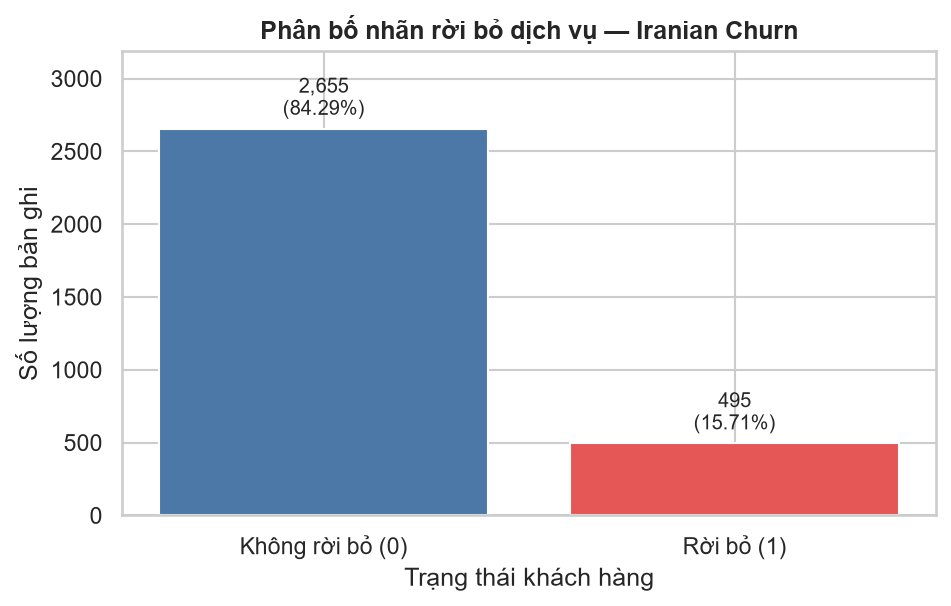

In [4]:
churn_counts = df["Churn"].value_counts().sort_index()
churn_rate = df["Churn"].mean()
print(f"Tỉ lệ Churn: {churn_rate:.2%} (Churn=1: {churn_counts[1]:,}, Churn=0: {churn_counts[0]:,})")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(
    ["Không rời bỏ (0)", "Rời bỏ (1)"],
    [churn_counts[0], churn_counts[1]],
    color=["#4C78A8", "#E45756"],
)
for bar in bars:
    h = bar.get_height()
    ax.annotate(
        f"{h:,}\n({h / len(df):.2%})",
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9.5,
    )
ax.set_title("Phân bố nhãn rời bỏ dịch vụ — Iranian Churn", fontweight="bold")
ax.set_xlabel("Trạng thái khách hàng")
ax.set_ylabel("Số lượng bản ghi")
ax.set_ylim(0, max(churn_counts) * 1.2)
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "iranian_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Tỉ lệ Churn theo các biến phân loại (`Complains`, `Tariff Plan`, `Status`, `Age Group`)

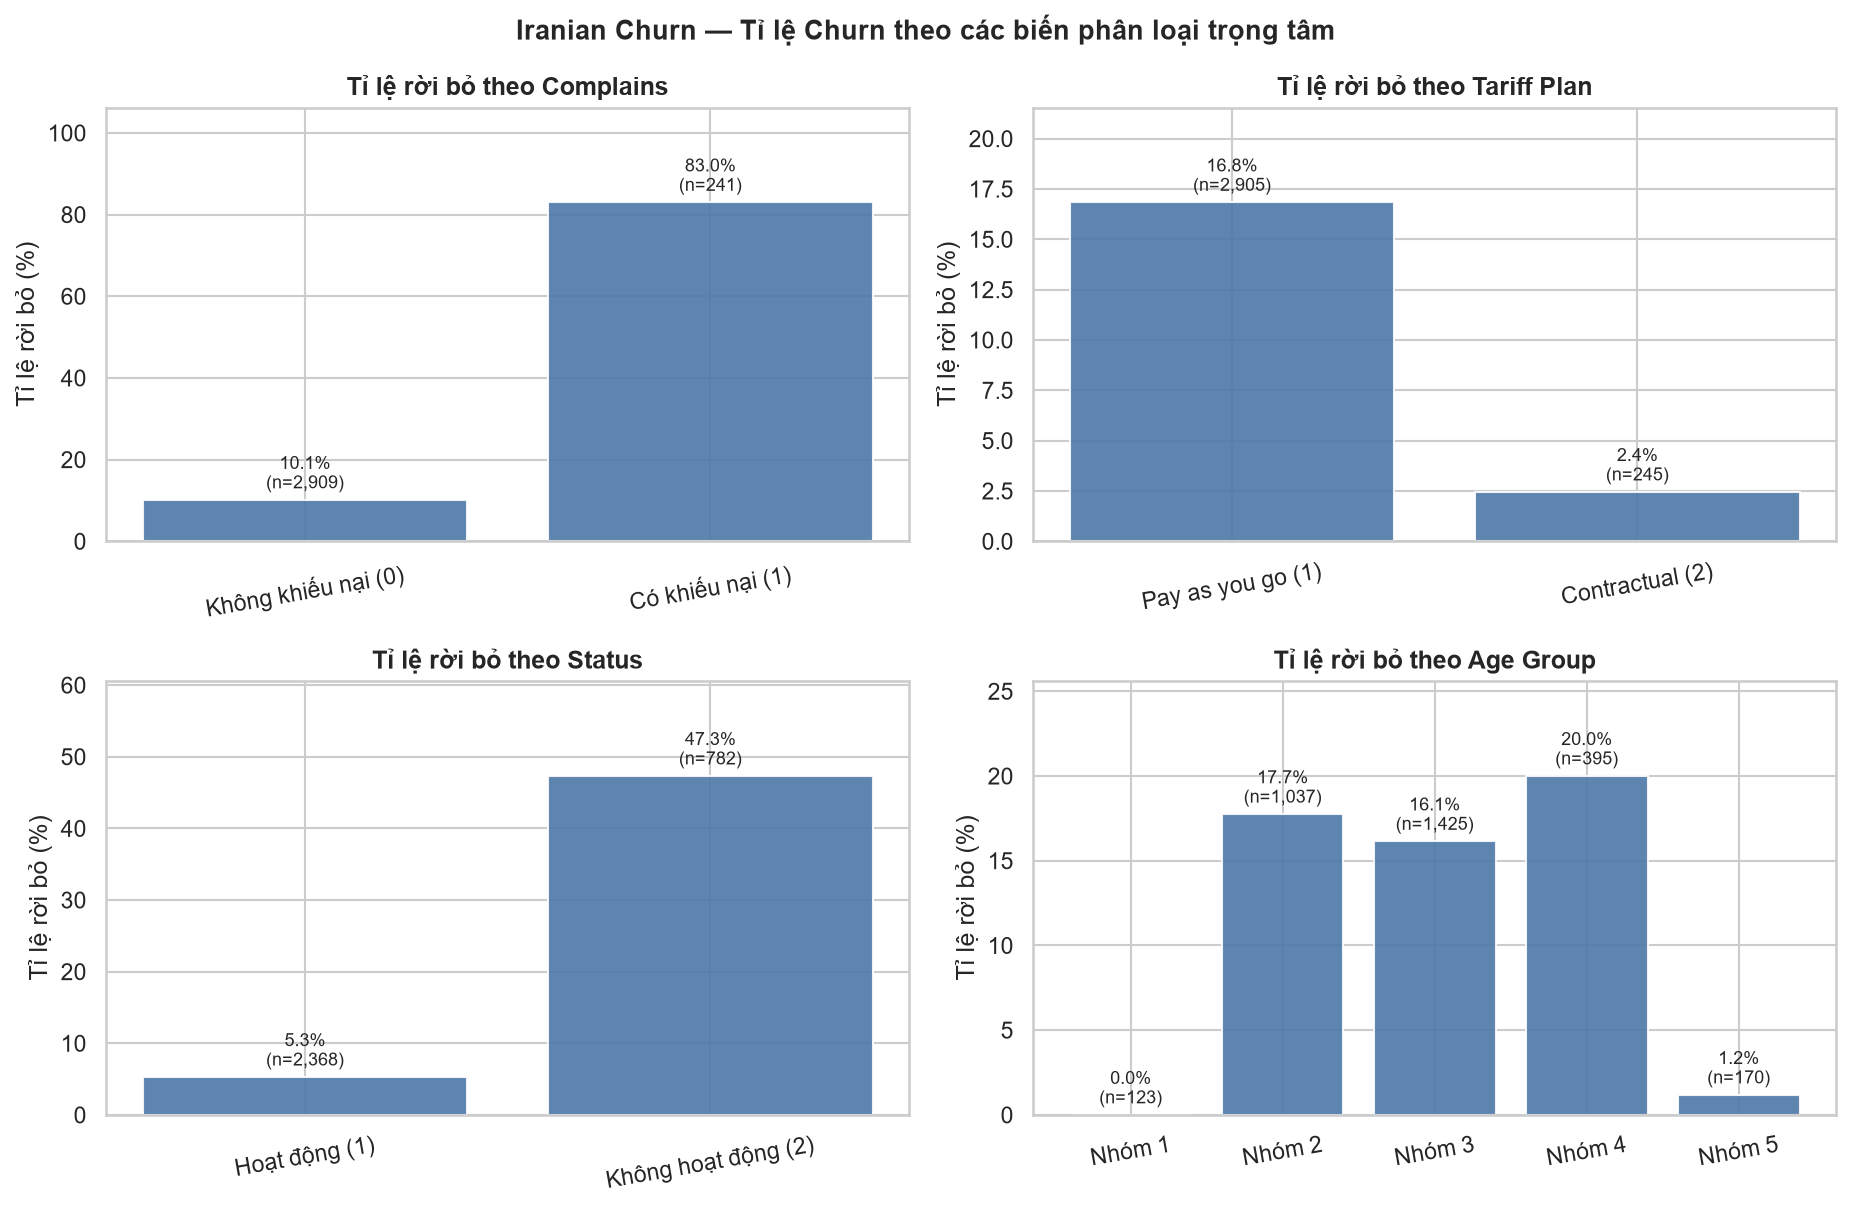

In [5]:
cat_specs = [
    ("Complains", {0: "Không khiếu nại (0)", 1: "Có khiếu nại (1)"}),
    ("Tariff Plan", {1: "Pay as you go (1)", 2: "Contractual (2)"}),
    ("Status", {1: "Hoạt động (1)", 2: "Không hoạt động (2)"}),
    ("Age Group", {1: "Nhóm 1", 2: "Nhóm 2", 3: "Nhóm 3", 4: "Nhóm 4", 5: "Nhóm 5"}),
]

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2))
for ax, (col, label_map) in zip(axes.ravel(), cat_specs):
    summary = df.groupby(col)["Churn"].agg(["mean", "count"]).sort_index()
    x_labels = [label_map.get(k, str(k)) for k in summary.index]
    bars = ax.bar(x_labels, summary["mean"] * 100, color="#4C78A8", alpha=0.9)
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.annotate(
            f"{row['mean']:.1%}\n(n={int(row['count']):,})",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
        )
    ax.set_title(f"Tỉ lệ rời bỏ theo {col}", fontweight="bold")
    ax.set_ylabel("Tỉ lệ rời bỏ (%)")
    ax.set_ylim(0, max(summary["mean"] * 100) * 1.28)
    ax.tick_params(axis="x", rotation=10)

fig.suptitle("Iranian Churn — Tỉ lệ Churn theo các biến phân loại trọng tâm", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "iranian_categorical_churn.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Phân bố biến số theo nhãn (`Subscription Length`, `Frequency of use`, `Charge Amount`, `Seconds of Use`)

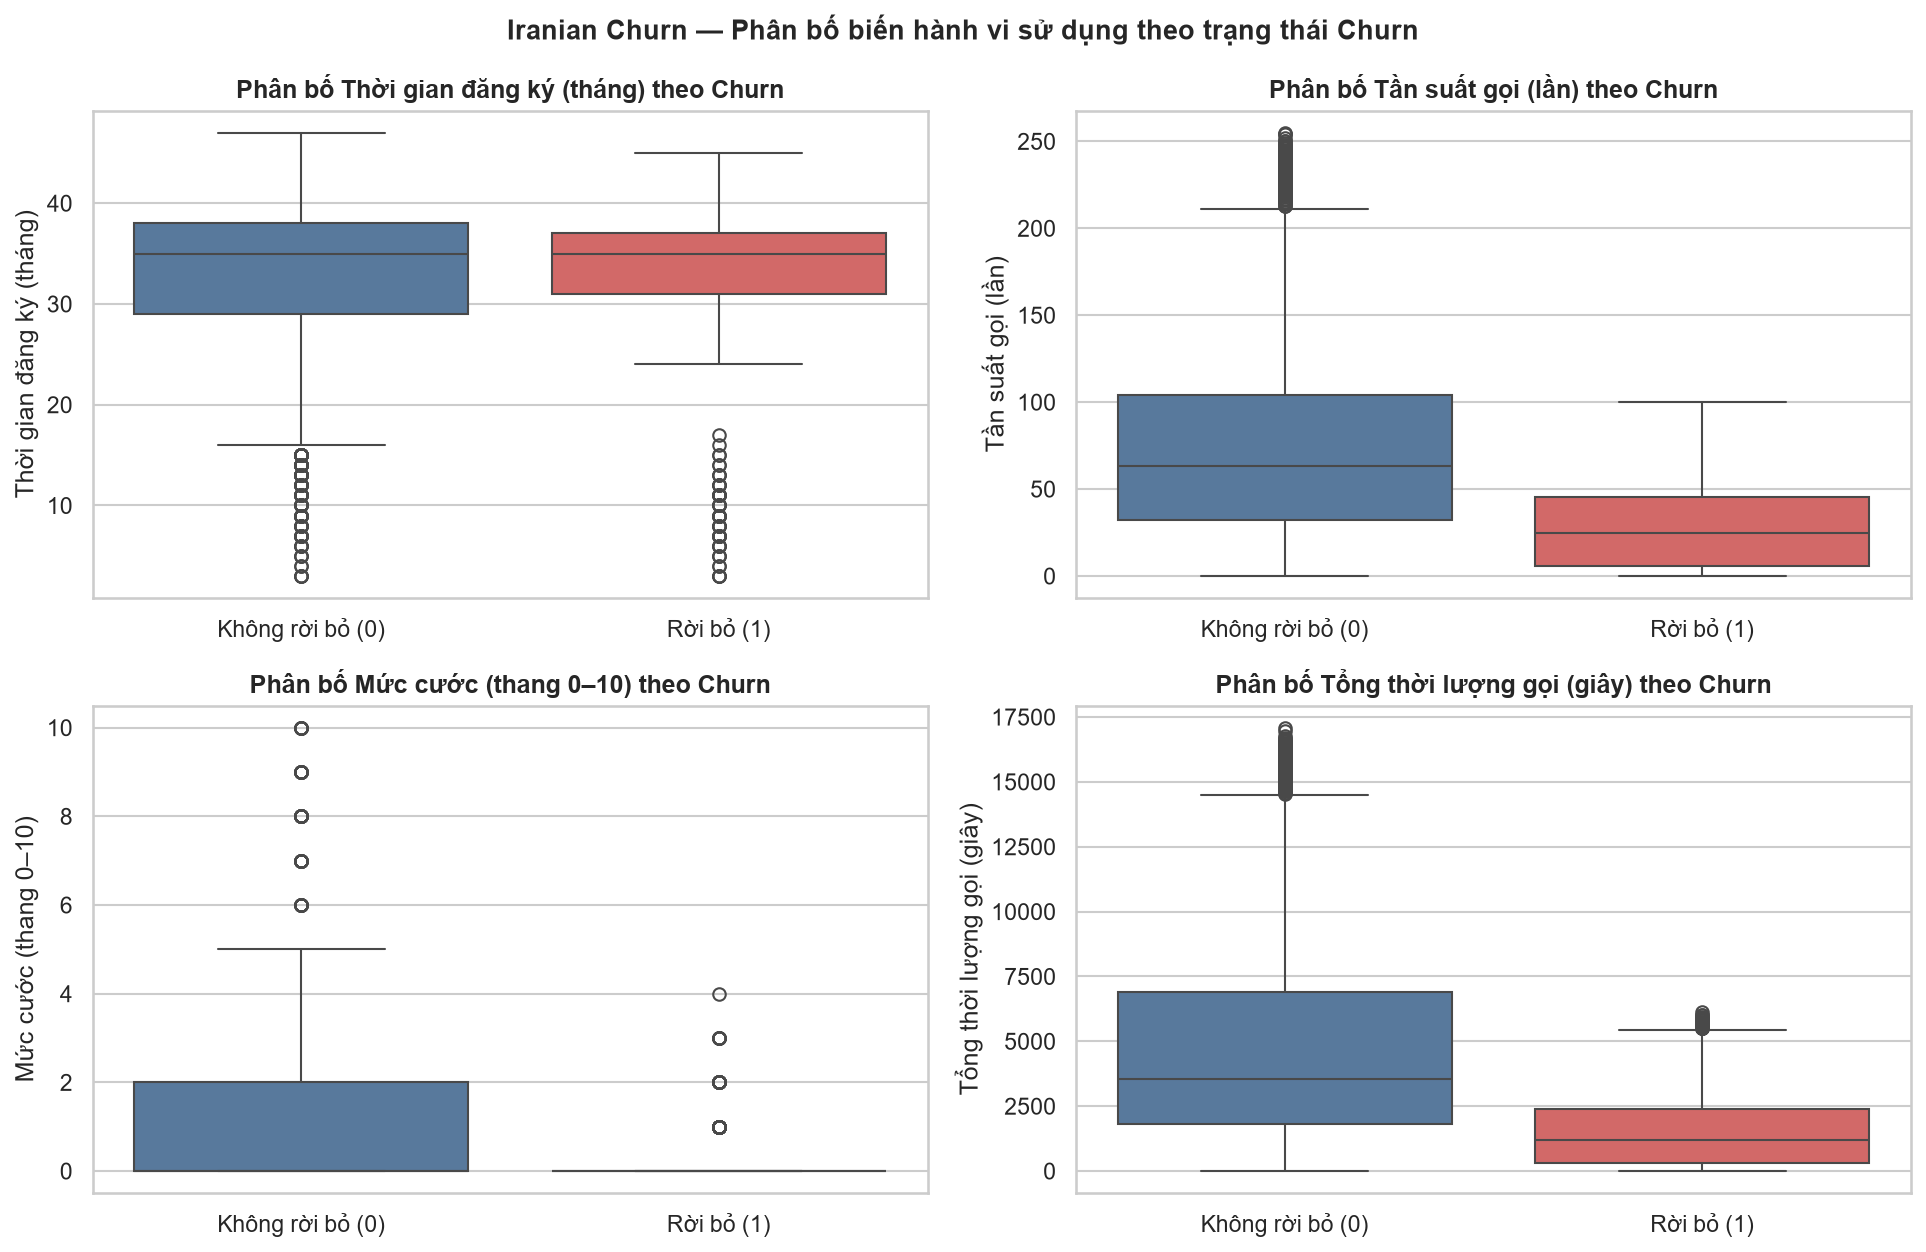

In [6]:
num_specs = [
    ("Subscription Length", "Thời gian đăng ký (tháng)"),
    ("Frequency of use", "Tần suất gọi (lần)"),
    ("Charge Amount", "Mức cước (thang 0–10)"),
    ("Seconds of Use", "Tổng thời lượng gọi (giây)"),
]

df_plot = df.copy()
df_plot["Nhãn Churn"] = df_plot["Churn"].map({0: "Không rời bỏ (0)", 1: "Rời bỏ (1)"})

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (col, title_vi) in zip(axes.ravel(), num_specs):
    sns.boxplot(
        data=df_plot,
        x="Nhãn Churn",
        y=col,
        hue="Nhãn Churn",
        palette={"Không rời bỏ (0)": "#4C78A8", "Rời bỏ (1)": "#E45756"},
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Phân bố {title_vi} theo Churn", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(title_vi)

fig.suptitle("Iranian Churn — Phân bố biến hành vi sử dụng theo trạng thái Churn", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "iranian_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Ma trận tương quan & biến dư thừa (`Customer Value`, `Age` vs `Age Group`)

Top tương quan tuyệt đối với Customer Value:
Frequency of SMS           0.9249
Seconds of Use             0.4151
Status                    -0.4130
Frequency of use           0.4016
Churn                     -0.2891
Distinct Called Numbers    0.2848
Name: Customer Value, dtype: float64

Tương quan giữa Age và Age Group: 0.9608
Tương quan giữa Seconds of Use và Frequency of use: 0.9465


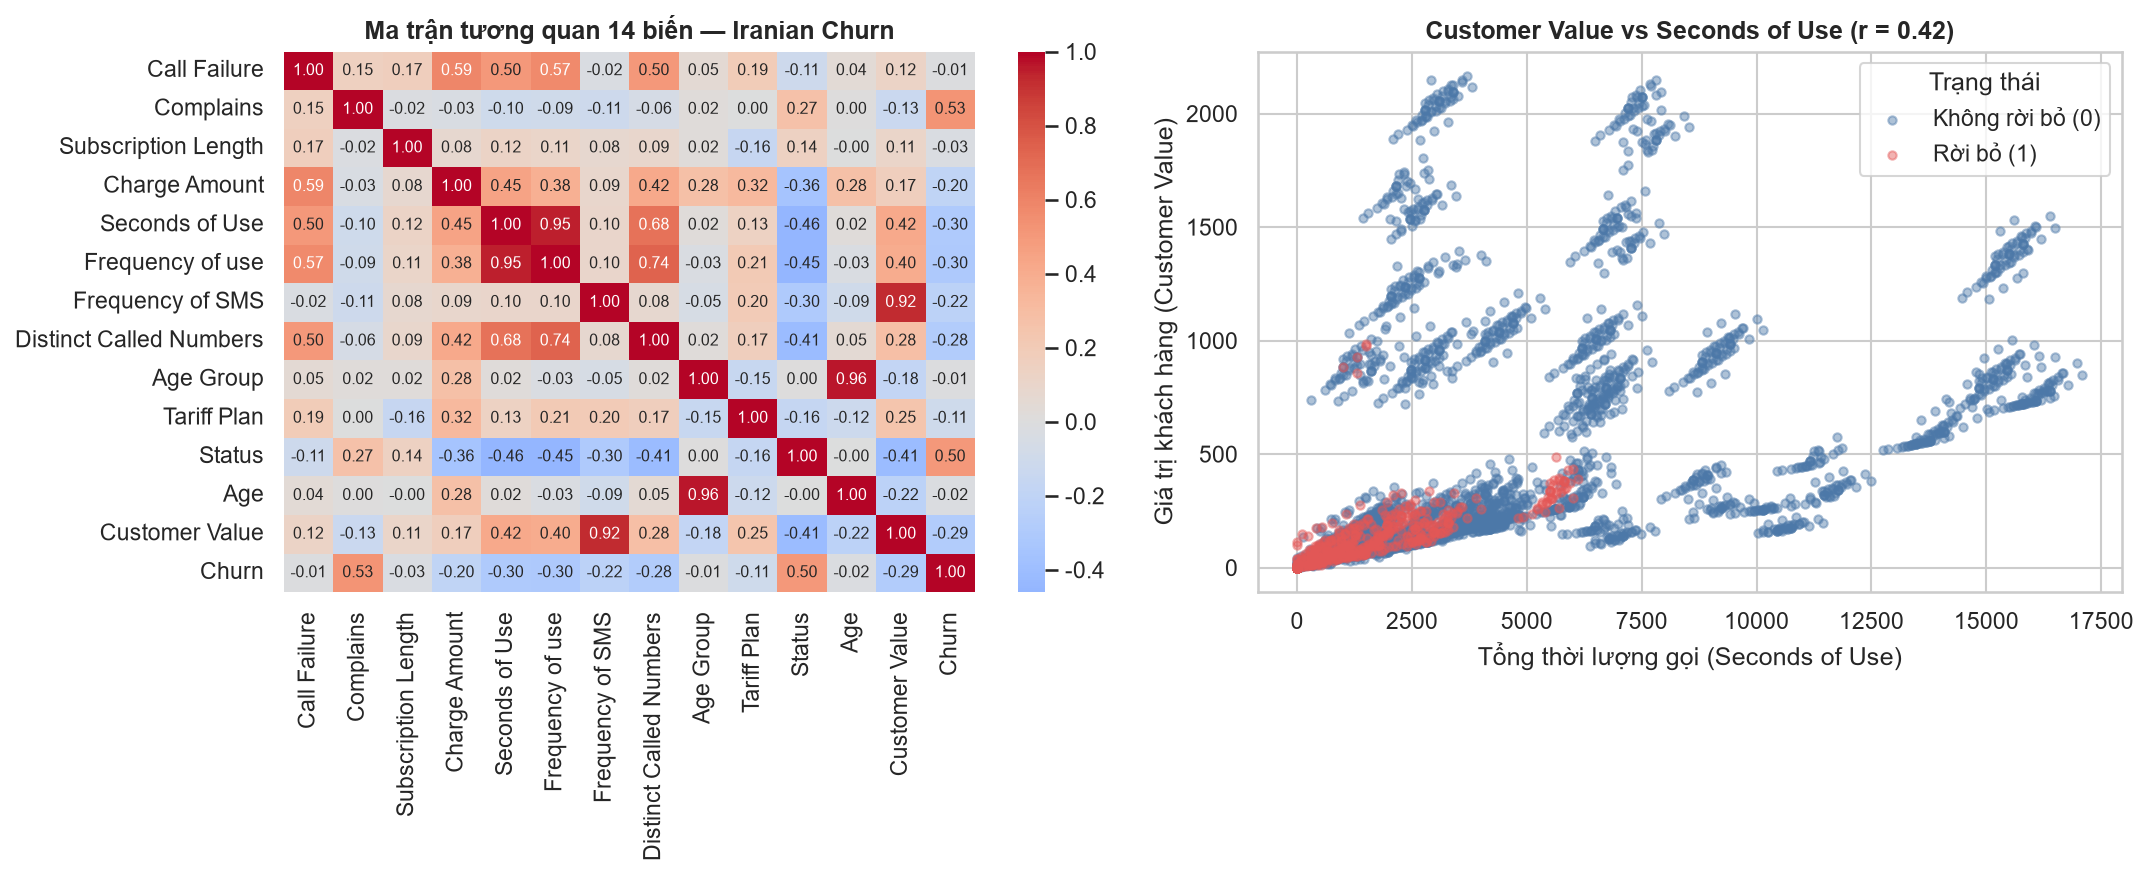

In [7]:
corr = df.corr(numeric_only=True)
print("Top tương quan tuyệt đối với Customer Value:")
print(corr["Customer Value"].drop("Customer Value").sort_values(key=abs, ascending=False).head(6).round(4))
print("\nTương quan giữa Age và Age Group:", round(df["Age"].corr(df["Age Group"]), 4))
print("Tương quan giữa Seconds of Use và Frequency of use:", round(df["Seconds of Use"].corr(df["Frequency of use"]), 4))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7.5}, ax=axes[0])
axes[0].set_title("Ma trận tương quan 14 biến — Iranian Churn", fontweight="bold")

for label_val, name_vi, color in [(0, "Không rời bỏ (0)", "#4C78A8"), (1, "Rời bỏ (1)", "#E45756")]:
    sub = df[df["Churn"] == label_val]
    axes[1].scatter(sub["Seconds of Use"], sub["Customer Value"], alpha=0.45, s=16, label=name_vi, color=color)
axes[1].set_title("Customer Value vs Seconds of Use (r = {:.2f})".format(corr.loc["Customer Value", "Seconds of Use"]), fontweight="bold")
axes[1].set_xlabel("Tổng thời lượng gọi (Seconds of Use)")
axes[1].set_ylabel("Giá trị khách hàng (Customer Value)")
axes[1].legend(title="Trạng thái")

fig.tight_layout()
fig.savefig(FIGURES_EDA_DIR / "iranian_correlation_redundancy.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Phát hiện → Hệ quả cho mô hình

1. **Mất cân bằng lớp (15.71% churn, 495/3,150):** Accuracy đơn thuần gây ngộ nhận. → **Hệ quả:** Dùng PR-AUC (Average Precision), ROC-AUC, F1 và tối ưu ngưỡng theo chi phí trên validation; dùng `class_weight="balanced_subsample"` cho Random Forest.
2. **300 dòng trùng hoàn toàn & 14 nhóm trùng đặc trưng nhưng khác nhãn:** Chia ngẫu nhiên theo dòng (row-wise) làm rò rỉ 71 dòng test trùng đặc trưng với train (seed 42). → **Hệ quả:** Bắt buộc dùng **group-aware split** (`StratifiedGroupKFold` trên hash vector đặc trưng) và kiểm chứng độ ổn định qua 10 seed.
3. **Quan hệ phi tuyến và cụm tương tác rõ (`Complains`, `Status`, `Seconds of Use`, `Frequency of use`):** Khách hàng có khiếu nại (`Complains = 1`) churn tới ~83.0% so với ~10.1% khi không khiếu nại; người dùng ít gọi/không hoạt động tách biệt rất mạnh. → **Hệ quả:** Mô hình cây/ensemble (Random Forest) nắm bắt ngưỡng phi tuyến vượt trội so với mô hình tuyến tính (RF AP ≈ 0.912 vs LogReg AP ≈ 0.758).
4. **Biến dư thừa & tương quan cao:** `Age` và `Age Group` có tương quan rất cao ($r \approx 0.96$); `Customer Value` tương quan mạnh với `Frequency of SMS` ($r \approx 0.92$) và `Seconds of Use` ($r \approx 0.41$). → **Hệ quả:** Random Forest ít nhạy cảm hơn với đa cộng tuyến, nhưng cần chú ý khi giải thích SHAP / feature importance để không phân tán trọng số.
5. **Rủi ro rò rỉ thời gian ở `Complains`, `Status`, `Customer Value`:** Tài liệu UCI nêu đặc trưng tổng hợp tháng 1–9 và nhãn ở tháng 12, nhưng CSV thiếu timestamp từng dòng. → **Hệ quả:** Cần đánh dấu cảnh báo trong `docs/data_dictionary.md` và xác nhận provenance với chủ dữ liệu (P0).